In [2]:
import numpy as np
import pandas as pd
import xsim
import xtools as xt
import matplotlib.pyplot as plt
from pyqubo import Array, Constraint, solve_qubo
from openjij import SQASampler, SASampler
from typing import Callable, Dict, List, Union

from atm.flight.generator import ScenarioGenerator
from atm.optimizer.objective import get_obj_single_runway, calc_assign_time
from atm.separation import recat, faa

In [63]:
cf = xt.Config(dict(
    num=10,
    scenario=dict(
        interval=60,
        window=200,
        mode="mix",
        standard="recat",
        seed=0,
    ),
    penalty_coef=10,
))
sep = recat.TBS if cf.scenario.standard == "recat" else faa.TBS


In [4]:
def generate_scenario_and_obj(config, seed=None):
    if seed is not None:
        if hasattr(config, "config"):
            config.seed = seed
        else:
            config.set("seed", seed)
    gen = ScenarioGenerator(config.scenario)
    vols = gen(config.num)
    obj = get_obj_single_runway(vols, sep, penalty_coef=config.penalty_coef)
    return vols, obj


In [5]:
class MetropolisHastingsOptimizer:

    def __init__(
            self,
            num_var: int,
            objective: Callable,
            temp: float = 1.,
            seed: int = None,
    ):
        self.nx = num_var
        self.obj = objective
        self.T = temp

        # seeding
        self._seed: int = None
        self._rng: np.random.Generator = None
        self.seed(seed)

        # state holders
        self.x_best = None
        self.e_best = None

        self._logger = None

    def seed(self, seed: int = None) -> int:
        if seed is None:
            seed = np.random.randint(0, 1e+8)
        self._seed = seed
        self._rng = np.random.default_rng(seed)
        return seed

    def evaluate(self, x) -> float:
        val = self.obj(x)
        return val

    def initialize(self):
        self._logger = xsim.Logger()

    def _initial_sample(self, x_init = None):
        if x_init is None:
            return np.arange(self.nx)

        if isinstance(x_init, str) and x_init == "random":
            return self._rng.choice(
                np.arange(self.nx),
                self.nx, replace=False
            )
        elif x_init == "default":
            return np.arange(self.nx)

        return np.asarray(x_init)

    def log(self, x, e):
        self._logger.store(**dict(
            step=len(self._logger),
            xp=x, ep=e,
            x_best=self.x_best,
            e_best=self.e_best,
        )).flush()

    @property
    def result(self):
        ret = xsim.Retriever(self._logger)
        res = dict(
            step=ret.step(),
            e_proposed=ret.ep(),
            e_best=ret.e_best()
        )
        res_x_prop = {
            f"x_proposed_{i}": ret.xp(idx=i)
            for i in range(self.nx)
        }
        res_x_best = {
            f"x_best_{i}": ret.x_best(idx=i)
            for i in range(self.nx)
        }
        res = pd.DataFrame(dict(**res, **res_x_prop, **res_x_best))
        return res

    def sample(self, x, step):
        idx1, idx2 = self._rng.choice(np.arange(self.nx), 2, replace=False)
        x = np.squeeze(x)
        xp = x.copy()
        xp[idx1] = x[idx2]
        xp[idx2] = x[idx1]
        return xp

    def calc_accept_prob(self, ec, ep):
        de = ep - ec
        if de < 0:
            return 1
        r = np.exp(-de / self.T)
        return np.min([1, r])

    def select_best_solution(self, xp, ep):
        if self.e_best >= ep:
            self.x_best = xp
            self.e_best = ep

    def optimize(self, max_iter: int, x_init: np.ndarray = None):
        self.initialize()

        # initial solution generation and evaluation
        self.x_best = xc = self._initial_sample(x_init)
        self.e_best = ec  = self.evaluate(xc)
        self.log(xc, ec)

        # main loop
        for step in range(1, max_iter+1):
            # sample and evaluation
            xp = self.sample(xc, step)
            ep = self.evaluate(xp)

            # stochastic accepting
            r = self.calc_accept_prob(ec, ep)
            if r > self._rng.random():
                xc = xp
                ec = ep

            # select best solution
            self.select_best_solution(xp, ep)
            self.log(xp, ep)

test with ASP objective

In [6]:
vols, obj = generate_scenario_and_obj(cf)
vols.to_dataframe()


,code,ready,due,category,operation
0,VOL0001,35,235,D,D
1,VOL0002,55,255,C,A
2,VOL0003,85,285,D,D
3,VOL0004,121,321,A,A
4,VOL0005,172,372,D,D
5,VOL0006,198,398,F,A
6,VOL0007,247,447,E,A
7,VOL0008,253,453,B,A
8,VOL0009,255,455,C,A
9,VOL0010,312,512,E,A


In [7]:
algo = MetropolisHastingsOptimizer(cf.num, obj)
algo.optimize(5000)


best cost: 687.3666381835938


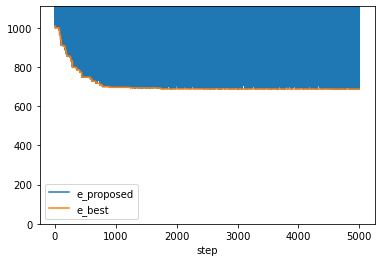

In [8]:
result = algo.result
result.plot(x="step", y=["e_proposed", "e_best"])
plt.ylim(0, result.e_best.max() * 1.1)
print("best cost:", result.e_best.min())

In [9]:
assign_times = calc_assign_time(algo.x_best, vols, sep)
assign_times = assign_times[algo.x_best]

In [119]:
class PairwiseSwapMetropolisHastingsOptimizer(MetropolisHastingsOptimizer):

    def __init__(
            self,
            num_var: int,
            objective: Callable,
            items: List,
            separation_cost: Callable,
            temp: float = 1.,
            sampler = SASampler,
            seed: int = None,
    ):
        super().__init__(num_var, objective, temp=temp, seed=seed)

        self.sampler = sampler()
        self.X = items
        self.sep = separation_cost
        
        self._e_sample_p = None
        self._e_sample_c = None

    def _get_S(self):
        def sf(vol1, vol2):
            return self.sep(vol1, vol2)
        return sf
    
    def _prob(self, e):
        return np.exp(-1*e)
    
    def calc_accept_prob(self, ec, ep):
        prob_ec = self._prob(ec)
        prob_ep = self._prob(ep)
        prob_sc = self._prob(self._e_sample_c)
        prob_sp = self._prob(self._e_sample_p)
        
        r = np.min([1, prob_ep * prob_sc / prob_ec * prob_sp])
        return r
    
    def sample(self, x, step):
        print("given x:", x)
        # prepare base queue
        original_queue = [self.X[i] for i in x]
        # calc pair shift size
        shift_by_step = (step - 1) % 2
        # prepare separation func
        S = self._get_S()
        
        # pairing
        indices_of_vol_in_original_queue = [[i, i+1] for i in range(shift_by_step, cf.num-1, 2)]
        print("pair indx:", indices_of_vol_in_original_queue)
        print("org_queue:", original_queue)
        ks = [[original_queue[i], original_queue[j]] for i, j in indices_of_vol_in_original_queue]
        
        # define variable X
        xs = Array.create("x", shape=len(ks), vartype="BINARY")
        
        # intra-pair cost
        e_in = Constraint(sum([
            S(vol1, vol2) * (1 - x) + S(vol2, vol1)
            for (vol1, vol2), x in zip(ks, xs)
        ]), "inner")
        
        # convert iterator of var to list
        lxs = list(xs)
        # external-pair cost
        e_ex = Constraint(sum([
            (S(j2, k2) - S(j2, k1)) * xk + (S(j1, k1) - S(j2, k1)) * xk + (S(j1, k2) - S(j2, k1)) * xj * xk
            for (j1, j2), (k1, k2), xj, xk in zip(ks[:-1], ks[1:], lxs[:-1], lxs[1:])
        ]), "external")
        
        # build model and qubo
        e = e_in + e_ex
        model = e.compile()
        qubo, bias = model.to_qubo()
        
        # sample from qubo
        sampleset = self.sampler.sample_qubo(qubo)
        sol = sampleset.first
        
        # reconstruct queue from sampled solution by swapping
        xdict = sol.sample
        queue_sampled = sum([
            indices_of_vol_in_original_queue[i][::-1] if xdict["x[{}]".format(i)] else indices_of_vol_in_original_queue[i]
            for i in range(len(ks))
        ], [])
        
        self._e_sample_p = sol.energy + bias
        self._e_sample_c = bias
        
        return queue_sampled

In [120]:
cf.num=4
vols, obj = generate_scenario_and_obj(cf)
vols.to_dataframe()

,code,ready,due,category,operation
0,VOL0001,35,235,E,D
1,VOL0002,55,255,A,D
2,VOL0003,85,285,A,D
3,VOL0004,121,321,E,A


In [121]:
algo = PairwiseSwapMetropolisHastingsOptimizer(cf.num // 2, obj, vols, sep)
algo.optimize(10)

given x: [0 1]
pair indx: [[0, 1], [2, 3]]
org_queue: [<atm.flight.flight.Flight object at 0x177e766a0>, <atm.flight.flight.Flight object at 0x177e76a60>]


IndexError: list index out of range

In [11]:
algo = PairwiseSwapMetropolisHastingsOptimizer(cf.num // 2, obj, vols, sep)
original_x = np.arange(cf.num)
step = 1
print(original_x)
ks = algo.sample(original_x, step)
print("ks:", ks)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]
model: <cpp_pyqubo.Model object at 0x16b5f5670>
bias: 3001.0
Sample(sample={'x[0]': 1, 'x[10]': 1, 'x[11]': 1, 'x[12]': 1, 'x[13]': 1, 'x[14]': 1, 'x[1]': 1, 'x[2]': 1, 'x[3]': 1, 'x[4]': 1, 'x[5]': 1, 'x[6]': 1, 'x[7]': 1, 'x[8]': 1, 'x[9]': 1}, energy=-1447.0, num_occurrences=1)
ks: None


In [64]:
vols, obj = generate_scenario_and_obj(cf)
vols.to_dataframe()

,code,ready,due,category,operation
0,VOL0001,35,235,B,A
1,VOL0002,55,255,E,D
2,VOL0003,85,285,D,D
3,VOL0004,121,321,A,A
4,VOL0005,172,372,D,A
5,VOL0006,198,398,F,D
6,VOL0007,247,447,A,D
7,VOL0008,253,453,C,D
8,VOL0009,255,455,D,D
9,VOL0010,312,512,A,A


In [65]:
# initial queue
# vols = np.random.choice(np.arange(cf.num), cf.num, replace=False)
print("initial vols:", vols)

# num de iteration
step = 1

indices_of_vol_in_original_queue = [[i, i+1] for i in range((step-1) % 2, cf.num-1, 2)]
print("index set of pair:", indices_of_vol_in_original_queue)

ks = [[vols[i], vols[j]] for i, j in indices_of_vol_in_original_queue]
print("set of vol-pair:", ks)


initial vols: <atm.flight.scenario.Scenario object at 0x1775487c0>
index set of pair: [[0, 1], [2, 3], [4, 5], [6, 7], [8, 9]]
set of vol-pair: [[<atm.flight.flight.Flight object at 0x177501fd0>, <atm.flight.flight.Flight object at 0x16b5f13a0>], [<atm.flight.flight.Flight object at 0x17761b340>, <atm.flight.flight.Flight object at 0x17761bac0>], [<atm.flight.flight.Flight object at 0x177612250>, <atm.flight.flight.Flight object at 0x1775eaf10>], [<atm.flight.flight.Flight object at 0x16c209790>, <atm.flight.flight.Flight object at 0x16c209910>], [<atm.flight.flight.Flight object at 0x16c209700>, <atm.flight.flight.Flight object at 0x16c209820>]]


In [66]:
def get_S(separation):
    def fn(vol1, vol2):
        return separation(vol1, vol2)
    return fn

S = get_S(sep)

In [67]:
xs = Array.create("x", shape=len(ks), vartype="BINARY")
xs

Array([Binary('x[0]'), Binary('x[1]'), Binary('x[2]'), Binary('x[3]'), Binary('x[4]')])

In [68]:
e_in = Constraint(sum([
    S(vol1, vol2) * (1 - x) + S(vol2, vol1)
    for (vol1, vol2), x in zip(ks, xs)
]), "inner")
e_in

Constraint((((74.000000 * (1.000000 + (-1.000000 * Binary('x[4]')))) + 129.000000) + ((129.000000 * (1.000000 + (-1.000000 * Binary('x[3]')))) + 75.000000) + ((150.000000 * (1.000000 + (-1.000000 * Binary('x[2]')))) + 82.000000) + ((74.000000 * (1.000000 + (-1.000000 * Binary('x[1]')))) + 129.000000) + 0.000000 + (146.000000 * (1.000000 + (-1.000000 * Binary('x[0]')))) + 82.000000), 'inner')

In [69]:
lxs = list(xs)
e_ex = Constraint(sum([
    (S(j2, k2) - S(j2, k1)) * xk + (S(j1, k1) - S(j2, k1)) * xk + (S(j1, k2) - S(j2, k1)) * xj * xk
    for (j1, j2), (k1, k2), xj, xk in zip(ks[:-1], ks[1:], lxs[:-1], lxs[1:])
]), "external")
e_ex

Constraint(((((-13.000000 * Binary('x[3]')) * Binary('x[4]')) + (-15.000000 * Binary('x[4]')) + (39.000000 * Binary('x[4]'))) + (((-7.000000 * Binary('x[2]')) * Binary('x[3]')) + (0.000000 * Binary('x[3]')) + (-7.000000 * Binary('x[3]'))) + (((21.000000 * Binary('x[1]')) * Binary('x[2]')) + (77.000000 * Binary('x[2]')) + (-55.000000 * Binary('x[2]'))) + 0.000000 + ((-18.000000 * Binary('x[0]')) * Binary('x[1]')) + (0.000000 * Binary('x[1]')) + (35.000000 * Binary('x[1]'))), 'external')

In [70]:
# build qubo model
e = e_in + e_ex
model = e.compile()
qubo, bias = model.to_qubo()

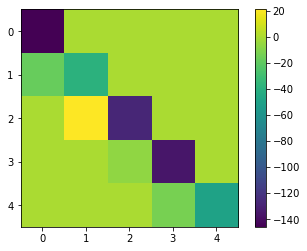

In [71]:
Q = np.zeros((len(ks), len(ks)))
for (str_idx1, str_idx2), qij in qubo.items():
    idx1 = int(str_idx1.replace("x[", "").replace("]", ""))
    idx2 = int(str_idx2.replace("x[", "").replace("]", ""))
    Q[idx1, idx2] = qij

plt.imshow(Q)
plt.colorbar()

In [74]:
print(bias)
print(Q)

1070.0
[[-146.    0.    0.    0.    0.]
 [ -18.  -39.    0.    0.    0.]
 [   0.   21. -128.    0.    0.]
 [   0.    0.   -7. -136.    0.]
 [   0.    0.    0.  -13.  -50.]]
